## 0. Описание задачи

Таблица содержит более 23 тысяч отзывов пассажиров об авиакомпаниях. Для каждого отзыва указаны оценки аспектов обслуживания (комфорт кресла, бортпроводники, еда, наземное обслуживание, цена/качество и др.), тип путешественника, класс обслуживания и ответ на вопрос «Рекомендуете ли вы авиакомпанию?». Требуется по этим признакам предсказать ответ Recommended (yes/no). Это задача классификации с двумя классами, классы несбалансированы (34% / 66%).

### 1. Чтение/подготовка данных

In [342]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
%matplotlib inline
sns.set_theme(style='whitegrid')

In [343]:
url = "https://raw.githubusercontent.com/arasash1/ML/main/homework_1/Airline_review.csv"
data = pd.read_csv(url)
print(data.shape)
data.info()

(23171, 20)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23171 entries, 0 to 23170
Data columns (total 20 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Unnamed: 0              23171 non-null  int64  
 1   Airline Name            23171 non-null  object 
 2   Overall_Rating          23171 non-null  object 
 3   Review_Title            23171 non-null  object 
 4   Review Date             23171 non-null  object 
 5   Verified                23171 non-null  bool   
 6   Review                  23171 non-null  object 
 7   Aircraft                7129 non-null   object 
 8   Type Of Traveller       19433 non-null  object 
 9   Seat Type               22075 non-null  object 
 10  Route                   19343 non-null  object 
 11  Date Flown              19417 non-null  object 
 12  Seat Comfort            19016 non-null  float64
 13  Cabin Staff Service     18911 non-null  float64
 14  Food & Beverages        14

In [344]:
data.head()

,Unnamed: 0,Airline Name,Overall_Rating,Review_Title,Review Date,Verified,Review,Aircraft,Type Of Traveller,Seat Type,Route,Date Flown,Seat Comfort,Cabin Staff Service,Food & Beverages,Ground Service,Inflight Entertainment,Wifi & Connectivity,Value For Money,Recommended
0,0,AB Aviation,9,"""pretty decent airline""",11th November 2019,True,Moroni to Moheli. Turned out to be a pretty ...,NaN,Solo Leisure,Economy Class,Moroni to Moheli,November 2019,4.0,5.0,4.0,4.0,NaN,NaN,3.0,yes
1,1,AB Aviation,1,"""Not a good airline""",25th June 2019,True,Moroni to Anjouan. It is a very small airline...,E120,Solo Leisure,Economy Class,Moroni to Anjouan,June 2019,2.0,2.0,1.0,1.0,NaN,NaN,2.0,no
2,2,AB Aviation,1,"""flight was fortunately short""",25th June 2019,True,Anjouan to Dzaoudzi. A very small airline an...,Embraer E120,Solo Leisure,Economy Class,Anjouan to Dzaoudzi,June 2019,2.0,1.0,1.0,1.0,NaN,NaN,2.0,no
3,3,Adria Airways,1,"""I will never fly again with Adria""",28th September 2019,False,Please do a favor yourself and do not fly wi...,NaN,Solo Leisure,Economy Class,Frankfurt to Pristina,September 2019,1.0,1.0,NaN,1.0,NaN,NaN,1.0,no
4,4,Adria Airways,1,"""it ruined our last days of holidays""",24th September 2019,True,Do not book a flight with this airline! My fr...,NaN,Couple Leisure,Economy Class,Sofia to Amsterdam via Ljubljana,September 2019,1.0,1.0,1.0,1.0,1.0,1.0,1.0,no


Столбцы (признаки) имеют имена:

- `Unnamed: 0` - номер строки (служебный столбец)
- `Airline Name` - название авиакомпании
- `Overall_Rating` - общая оценка по шкале 1-10 (хранится как строка, значение `'n'` означает, что оценка не указана)
- `Review_Title`, `Review` - заголовок и текст отзыва
- `Review Date` - дата написания отзыва
- `Verified` - подтверждён ли отзыв (`True`/`False`)
- `Aircraft` - тип самолёта
- `Type Of Traveller` - тип путешественника (`Solo Leisure`, `Couple Leisure`, `Family Leisure`, `Business`)
- `Seat Type` - класс обслуживания (`Economy Class`, `Premium Economy`, `Business Class`, `First Class`)
- `Route` - маршрут
- `Date Flown` - месяц и год полёта
- `Seat Comfort`, `Cabin Staff Service`, `Food & Beverages`, `Ground Service`, `Inflight Entertainment`, `Wifi & Connectivity`, `Value For Money` - оценки отдельных аспектов обслуживания (целые числа, шкала 1-5)
- `Recommended` - **целевой признак**: порекомендует ли пассажир авиакомпанию (`yes`/`no`)

Типы признаков:

- **Количественные (числовые), дискретные:** 7 оценок аспектов (`Seat Comfort`, `Cabin Staff Service`, `Food & Beverages`, `Ground Service`, `Inflight Entertainment`, `Wifi & Connectivity`, `Value For Money`). Это целые числа на упорядоченной шкале, их можно считать числовыми.
- **Категориальные номинальные:** `Type Of Traveller`, `Seat Type`, `Airline Name`, `Aircraft`, `Route`.
- **Бинарные:** `Verified` (`True`/`False`) и целевой признак `Recommended` (`yes`/`no`).
- **Текстовые:** `Review_Title`, `Review`.
- **Даты:** `Review Date`, `Date Flown`.
- **Особый случай:** `Overall_Rating` по смыслу порядковый признак (1-10), но записан строкой и содержит значение `'n'` (нет оценки);

In [345]:
data['Type Of Traveller'] = data['Type Of Traveller'].astype('category')
data['Seat Type'] = data['Seat Type'].astype('category')

data.describe(include=['category'])

,Type Of Traveller,Seat Type
count,19433,22075
unique,4,4
top,Solo Leisure,Economy Class
freq,7120,19145


Первичная чистка:
- `Unnamed: 0` - индекс строки, удаляем
- удаляем полные дубликаты отзывов (иначе одна и та же запись может попасть и в train, и в test).

In [346]:
data = data.drop(columns='Unnamed: 0')
n_before = len(data)

data = data.drop_duplicates().reset_index(drop=True)
print('изначально строк:', n_before, ', удалено дубликатов:', n_before - len(data), ', осталось строк:', len(data))

изначально строк: 23171 , удалено дубликатов: 120 , осталось строк: 23051


## 2. Разбиение на обучающую и тестовую выборки

Разбиваем до любых вычислений статистик (средних, медиан, масштабирования), чтобы информация из теста не просочилась в обучение.
Используем `stratify=y`, чтобы доля классов в train и test была одинаковой.

In [347]:
X = data.drop(['Recommended'], axis = 1)
y = (data['Recommended'] == 'yes').astype(int)

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

N_train, d = X_train.shape
N_test,  d = X_test.shape

N_train, N_test, d

(16135, 6916, 18)

## 3. Визуализация и основные характеристики

изучаем обучающую выборку.

In [348]:
train = X_train.copy()
train['Recommended'] = y_train

rating_cols = ['Seat Comfort', 'Cabin Staff Service', 'Food & Beverages', 'Ground Service',
               'Inflight Entertainment', 'Wifi & Connectivity', 'Value For Money']

train[rating_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
Seat Comfort,13279.0,2.620077,1.467740,0.0,1.0,3.0,4.0,5.0
Cabin Staff Service,13209.0,2.873950,1.603608,0.0,1.0,3.0,4.0,5.0
Food & Beverages,10126.0,2.552834,1.525592,0.0,1.0,2.0,4.0,5.0
Ground Service,12827.0,2.354643,1.597102,1.0,1.0,1.0,4.0,5.0
Inflight Entertainment,7533.0,2.181999,1.489986,0.0,1.0,2.0,3.0,5.0
Wifi & Connectivity,4126.0,1.790596,1.324004,0.0,1.0,1.0,2.0,5.0
Value For Money,15463.0,2.449266,1.594153,0.0,1.0,2.0,4.0,5.0


**Интерпретация.** все оценки лежат в диапазоне 0–5. Средние значения низкие, медианы часто равны 1–2. в выборке много недовольных пассажиров, что согласуется с преобладанием класса `no`. Стандартные отклонения большие, то есть оценки сильно разбросаны. Самые низкие оценки у `Wifi & Connectivity` и `Inflight Entertainment`, но по ним очень много пропусков

,proportion
Recommended,
0,0.662
1,0.338


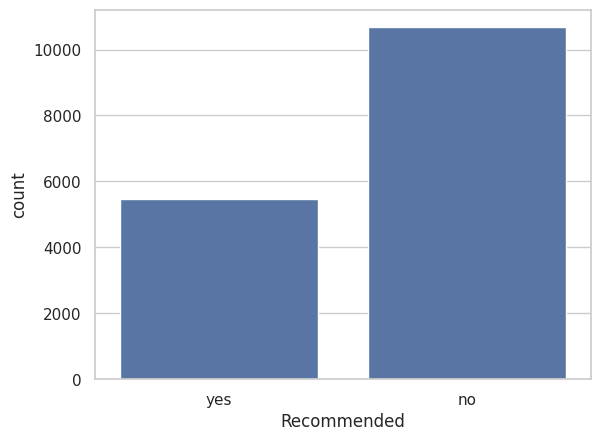

In [349]:
sns.countplot(x=train['Recommended'].map({0: 'no', 1: 'yes'}))
plt.xlabel('Recommended')
pass

y_train.value_counts(normalize=True).round(3)

**Интерпретация**. Классы несбалансированы: no составляет примерно 66% (10675 отзывов), yes примерно 34% (5460).

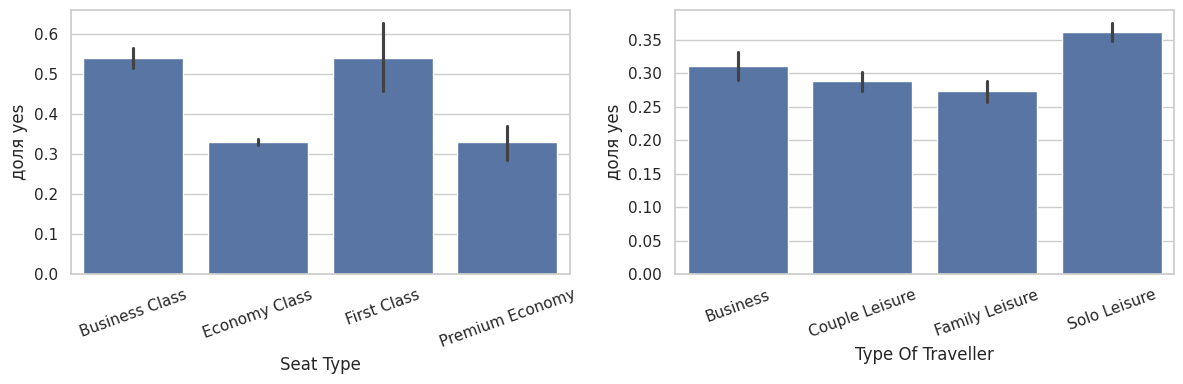

In [350]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(x='Seat Type', y='Recommended', data=train, ax=axes[0])
sns.barplot(x='Type Of Traveller', y='Recommended', data=train, ax=axes[1])
for ax in axes:
    ax.set_ylabel('доля yes')
    ax.tick_params(axis='x', rotation=20)
plt.tight_layout()
pass

**Интерпретация.** Доля пассажиров, рекомендующих авиакомпанию, зависит от класса обслуживания: в бизнес и первом классе она около 54%, в эконом- и премиум-эконом около 33%. Отметим, что первый класс встречается редко (135 отзывов в обучающей выборке), поэтому для него оценка менее надёжна. По типу путешественника различия небольшие: от 27% (семейные поездки) до 36% (одиночные). Значит, категориальные признаки несут некоторую информацию, но не определяют ответ.

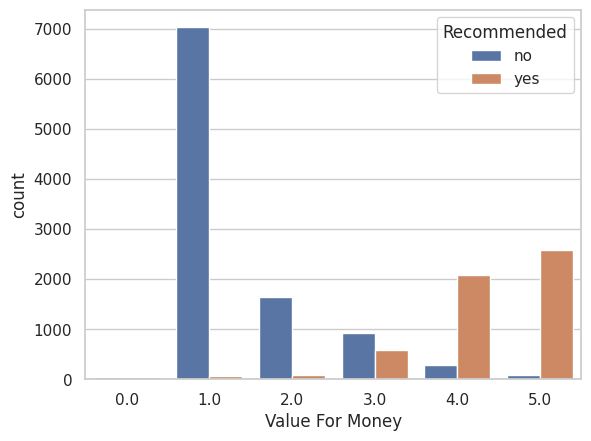

In [351]:
sns.countplot(x='Value For Money', hue=train['Recommended'].map({0: 'no', 1: 'yes'}), data=train)
plt.legend(title='Recommended')
pass

**Интерпертация**. Оценки хорошо разделяют классы: среди пассажиров, поставивших 1, рекомендуют авиакомпанию только 71 из 7097 человек, а среди поставивших 5 не рекомендуют только 76 из 2658. Оценки 4-5 почти полностью относятся к yes, а 1-2 к no; 3 - переходная зона. Отдельные отзывы с оценкой 0 находятся вне шкалы 1-5, этот вопрос разберём дальше

Text(0.5, 1.0, 'Корреляционная матрица (train)')

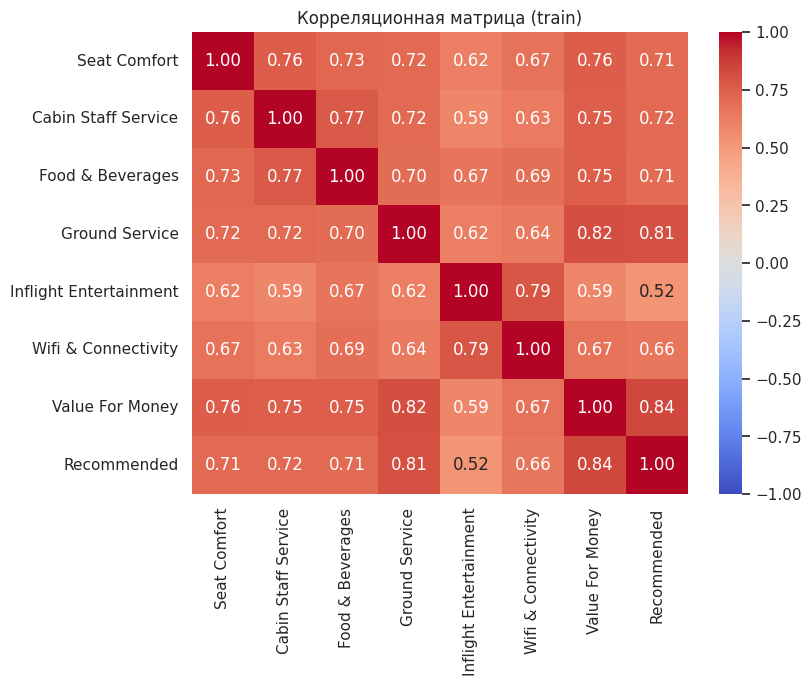

In [352]:
corr_cols = ['Seat Comfort', 'Cabin Staff Service', 'Food & Beverages', 'Ground Service',
               'Inflight Entertainment', 'Wifi & Connectivity', 'Value For Money']
corr = train[corr_cols + ['Recommended']].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Корреляционная матрица (train)')

**Интерпретация.** Все оценки положительно коррелируют с целевым признаком. Сильнее всего - Value For Money (0.84) и Ground Service (0.81); у Seat Comfort, Cabin Staff Service и Food & Beverages корреляция около 0.71-0.72, у Wifi & Connectivity 0.66, слабее всего у Inflight Entertainment (0.52). Между собой оценки тоже сильно коррелируют (в большинстве пар 0.6-0.8, в среднем 0.70): пассажир, довольный перелётом, склонен завышать оценки всем аспектам сразу.

## 4. Выбросы

**Ошибки** нужно исправлять (по возможности) или удалять. **Выбросы** (объекты, сильно отличающиеся от основной массы) несут информацию о хвостах распределения, и просто выкидывать их неправильно.

Оценки аспектов обслуживания лежат на шкале 1-5. Проверим, так ли это в таблице: посчитаем, сколько раз встречается каждое значение.

In [353]:
train[rating_cols].apply(pd.Series.value_counts).T.fillna(0).astype(int)

,0.0,1.0,2.0,3.0,4.0,5.0
Seat Comfort,97,4446,1975,2536,2337,1888
Cabin Staff Service,88,4172,1621,2019,2054,3255
Food & Beverages,168,3707,1365,1696,1625,1565
Ground Service,0,6605,1132,1247,1622,2221
Inflight Entertainment,371,3350,883,1198,928,803
Wifi & Connectivity,1,2818,326,348,291,342
Value For Money,97,7097,1719,1520,2372,2658


В таблице встречается значение `0`, хотя шкала на сайте начинается с 1.

Скорее всего, оценку не поставили, а в таблицу попал ноль. Это **ошибка данных**, а не выброс.

In [354]:
X_train[rating_cols] = X_train[rating_cols].replace(0, np.nan)
X_test[rating_cols]  = X_test[rating_cols].replace(0, np.nan)

X_train[rating_cols].agg(['min', 'max']).T

,min,max
Seat Comfort,1.0,5.0
Cabin Staff Service,1.0,5.0
Food & Beverages,1.0,5.0
Ground Service,1.0,5.0
Inflight Entertainment,1.0,5.0
Wifi & Connectivity,1.0,5.0
Value For Money,1.0,5.0


Заменяем нули на пропуски `np.nan`: они будут заполнены медианой вместе с остальными пропусками.

**Проблема с `Overall_Rating`.** Этот признак — общая оценка по шкале 1–10.

In [355]:
tmp = pd.crosstab(train['Overall_Rating'], train['Recommended'])
tmp

Recommended,0,1
Overall_Rating,,
1,6519,1575
2,1606,23
3,928,35
4,523,54
5,383,194
6,130,351
7,39,773
8,23,1198
9,4,1253


1. **Ошибка записи.** Значения `10` в таблице нет вообще, зато среди оценок `1` много (1575) отзывов с `yes`. По-видимому, оценка `10` при сборе данных была обрезана до `1`. Из-за этого признак нельзя использовать как числовой
2. **Утечка целевого признака.** Общая оценка по сути то же самое, что ответ «рекомендую / не рекомендую»: её нельзя знать до того, как пассажир принял решение. Если оставить такой признак, качество получится завышенным, а модель бесполезной на практике (мы хотим предсказывать рекомендацию по конкретным аспектам обслуживания).

Поэтому **исключаем `Overall_Rating` из признаков.**

## 5. Пропущенные значения

In [356]:
miss = X_train.isna().sum().sort_values(ascending=False)
miss[miss > 0]

,0
Wifi & Connectivity,12010
Aircraft,11152
Inflight Entertainment,8973
Food & Beverages,6177
Ground Service,3308
Cabin Staff Service,3014
Seat Comfort,2953
Route,2623
Date Flown,2570
Type Of Traveller,2558


число пропусков по столбцам обучающей выборки уже посчитана выше.

- `Aircraft` (69% пропусков), `Wifi & Connectivity` (74%), `Inflight Entertainment` (56%) - **удаляем столбцы**: заполнять больше половины значений медианой значило бы придумывать данные.
- `Review_Title`, `Review` - свободный текст. Для метода ближайших соседей он не подходит без специальной обработки (например, TF-IDF), поэтому не используем.
- `Review Date`, `Date Flown` - даты. Для них нужна отдельная обработка.
- `Overall_Rating` - исключён (утечка и ошибка записи).
- Остальные признаки оставляем: 5 оценок аспектов (`Seat Comfort`, `Cabin Staff Service`, `Food & Beverages`, `Ground Service`, `Value For Money`), бинарный `Verified` и категориальные `Type Of Traveller`, `Seat Type`.

В оставшихся числовых признаках пропуски заполняем **медианой**, в категориальных - **самым частым значением (модой)**. Эти статистики считаем **только по обучающей выборке** и применяем и к train, и к test.

In [357]:
numeric_features = ['Seat Comfort', 'Cabin Staff Service', 'Food & Beverages', 'Ground Service', 'Value For Money']
binary_features = ['Verified']
categorical_features = ['Type Of Traveller', 'Seat Type']
features = numeric_features + binary_features + categorical_features

Xtr = X_train[features].copy()
Xte = X_test[features].copy()

# числовые: медиана по train
medians = Xtr[numeric_features].median()
Xtr[numeric_features] = Xtr[numeric_features].fillna(medians)
Xte[numeric_features] = Xte[numeric_features].fillna(medians)

# категориальные: мода по train
for c in categorical_features:
    mode = Xtr[c].mode()[0]          # было Xte - исправлено
    Xtr[c] = Xtr[c].fillna(mode)
    Xte[c] = Xte[c].fillna(mode)

print('пропусков в train:', Xtr.isna().sum().sum(), ', в test:', Xte.isna().sum().sum())
medians

пропусков в train: 0 , в test: 0


,0
Seat Comfort,3.0
Cabin Staff Service,3.0
Food & Beverages,2.0
Ground Service,1.0
Value For Money,2.0


## 6. Категориальные признаки

- `Verified` (True/False) — бинарный, переводим в 0/1;
- `Type Of Traveller` (4 значения) и `Seat Type` (4 значения) — небинарные, применяем векторизацию.

In [358]:
from sklearn.preprocessing import OneHotEncoder

cat_cols = ['Verified', 'Type Of Traveller', 'Seat Type'] #бинарный + номинальные

enc = OneHotEncoder(drop='if_binary', sparse_output=False)
enc.fit(Xtr[cat_cols])

dummies_tr = pd.DataFrame(enc.transform(Xtr[cat_cols]),
                          columns=enc.get_feature_names_out(), index=Xtr.index)
dummies_te = pd.DataFrame(enc.transform(Xte[cat_cols]),
                          columns=enc.get_feature_names_out(), index=Xte.index)

Xtr_enc = pd.concat((Xtr[numeric_features], dummies_tr), axis=1)
Xte_enc = pd.concat((Xte[numeric_features], dummies_te), axis=1)

print(Xtr_enc.shape, Xte_enc.shape)
list(Xtr_enc.columns)

(16135, 14) (6916, 14)


['Seat Comfort',
 'Cabin Staff Service',
 'Food & Beverages',
 'Ground Service',
 'Value For Money',
 'Verified_True',
 'Type Of Traveller_Business',
 'Type Of Traveller_Couple Leisure',
 'Type Of Traveller_Family Leisure',
 'Type Of Traveller_Solo Leisure',
 'Seat Type_Business Class',
 'Seat Type_Economy Class',
 'Seat Type_First Class',
 'Seat Type_Premium Economy']

## 7. Нормализация

Метод ближайших соседей основан на расстояниях между объектами, поэтому признаки с разным масштабом вносят неодинаковый вклад. Оценки аспектов лежат на шкале 1-5, а dummy-признаки принимают значения 0/1. Кроме того, масштаб важен для линейных моделей, которые мы запустим дальше.

Выполним **стандартизацию всех признаков**: для каждого признака вычтем среднее и разделим на стандартное отклонение. После этого у каждого признака среднее равно 0, а стандартное отклонение 1, и все признаки вносят одинаковый вклад в расстояние.

In [359]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler().fit(Xtr_enc)         # среднее и std по train
Xtr_s = pd.DataFrame(scaler.transform(Xtr_enc), columns=Xtr_enc.columns, index=Xtr_enc.index)
Xte_s = pd.DataFrame(scaler.transform(Xte_enc), columns=Xte_enc.columns, index=Xte_enc.index)

print(Xtr_s.shape, Xte_s.shape)
print('train:')
print(Xtr_s.describe().loc[['mean', 'std']].round(3).T)

(16135, 14) (6916, 14)
train:
                                  mean  std
Seat Comfort                       0.0  1.0
Cabin Staff Service               -0.0  1.0
Food & Beverages                   0.0  1.0
Ground Service                     0.0  1.0
Value For Money                    0.0  1.0
Verified_True                     -0.0  1.0
Type Of Traveller_Business         0.0  1.0
Type Of Traveller_Couple Leisure   0.0  1.0
Type Of Traveller_Family Leisure  -0.0  1.0
Type Of Traveller_Solo Leisure    -0.0  1.0
Seat Type_Business Class           0.0  1.0
Seat Type_Economy Class            0.0  1.0
Seat Type_First Class              0.0  1.0
Seat Type_Premium Economy         -0.0  1.0


In [360]:
print('test:')
print(Xte_s.describe().loc[['mean', 'std']].round(3).T)

test:
                                   mean    std
Seat Comfort                     -0.003  0.995
Cabin Staff Service              -0.004  1.004
Food & Beverages                  0.006  1.002
Ground Service                    0.004  1.000
Value For Money                   0.003  1.001
Verified_True                     0.018  0.999
Type Of Traveller_Business       -0.000  1.000
Type Of Traveller_Couple Leisure -0.008  0.995
Type Of Traveller_Family Leisure -0.007  0.995
Type Of Traveller_Solo Leisure    0.012  1.001
Seat Type_Business Class          0.001  1.001
Seat Type_Economy Class           0.010  0.989
Seat Type_First Class            -0.011  0.939
Seat Type_Premium Economy        -0.015  0.958


На тестовой выборке среднее и стандартное отклонение близки к 0 и 1, но не равны им точно: параметры масштабирования взяты из обучающей выборки, и тест в них не участвовал. Заметнее всего отличие у редких признаков

## 8. Классификатор ближайших соседей

In [361]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=10)
knn.fit(Xtr_s, y_train)

KNeighborsClassifier(n_neighbors=10)

## 9. Ошибки на обучающей и тестовой выборках, матрицы рассогласования, выбор k

Сначала для произвольного k = 10.

In [362]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

err_train = np.mean(y_train != knn.predict(Xtr_s))
err_test  = np.mean(y_test  != knn.predict(Xte_s))
print(f'k = 10: ошибка на train = {err_train:.4f}, на test = {err_test:.4f}')

k = 10: ошибка на train = 0.0487, на test = 0.0570


Теперь подберём оптимальное k.

Выбираем $k$ по кросс-валидации на обучающей выборке

- При $k = 1$ ошибка на тесте самая большая (10.6%)
- Примерно с $k \approx 9$ кривые почти перестают меняться: любое $k$ от 9 до 51 даёт ошибку на тесте 5.7-5.9%. Это значит, что точное значение $k$ здесь не критично.
- Минимум ошибки кросс-валидации достигается при $k = 37$ (5.4%), его и берём.

оптимальное k по кросс-валидации: 37


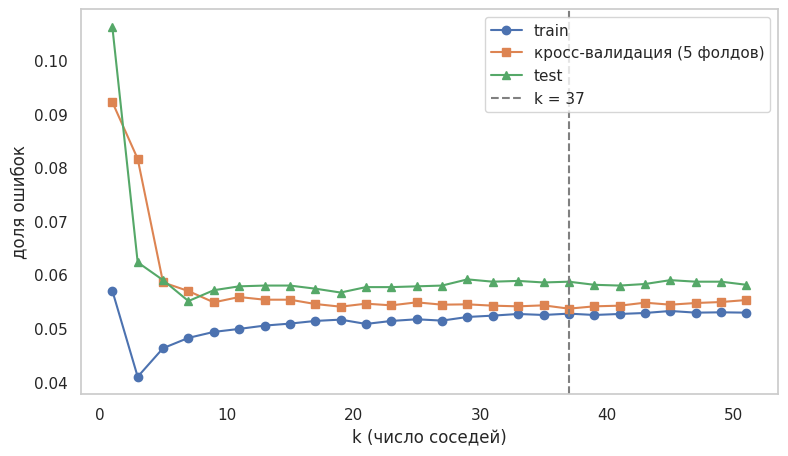

k,1,3,5,9,15,23,31,41,51
train,0.0570,0.0410,0.0463,0.0493,0.0509,0.0514,0.0524,0.0527,0.0529
CV,0.0922,0.0816,0.0586,0.0548,0.0553,0.0543,0.0542,0.0542,0.0553
test,0.1063,0.0623,0.0590,0.0571,0.0580,0.0577,0.0587,0.0580,0.0581


In [363]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

ks = list(range(1, 52, 2))
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

train_err, cv_err, test_err = [], [], []
for k in ks:
    m = KNeighborsClassifier(n_neighbors=k)
    cv_err.append(1 - cross_val_score(m, Xtr_s, y_train, cv=cv).mean())
    m.fit(Xtr_s, y_train)
    train_err.append(np.mean(y_train != m.predict(Xtr_s)))
    test_err.append(np.mean(y_test  != m.predict(Xte_s)))

best_k = ks[int(np.argmin(cv_err))]
print('оптимальное k по кросс-валидации:', best_k)

plt.figure(figsize=(9, 5))
plt.plot(ks, train_err, 'o-', label='train')
plt.plot(ks, cv_err, 's-', label='кросс-валидация (5 фолдов)')
plt.plot(ks, test_err, '^-', label='test')
plt.axvline(best_k, color='gray', ls='--', label=f'k = {best_k}')
plt.xlabel('k (число соседей)'); plt.ylabel('доля ошибок'); plt.legend(); plt.grid()
plt.show()

errors = pd.DataFrame({'k': ks, 'train': train_err, 'CV': cv_err, 'test': test_err}).set_index('k')
errors.loc[[1, 3, 5, 9, 15, 23, 31, 41, 51]].round(4).T

k = 37: ошибка на train = 0.0527, на test = 0.0587


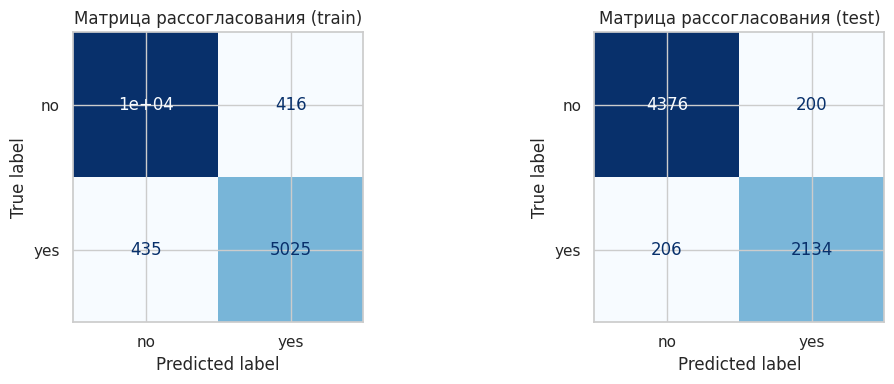

              precision    recall  f1-score   support

          no      0.955     0.956     0.956      4576
         yes      0.914     0.912     0.913      2340

    accuracy                          0.941      6916
   macro avg      0.935     0.934     0.934      6916
weighted avg      0.941     0.941     0.941      6916



In [364]:
knn = KNeighborsClassifier(n_neighbors=best_k).fit(Xtr_s, y_train)
pred_train = knn.predict(Xtr_s)
pred_test  = knn.predict(Xte_s)

print(f'k = {best_k}: ошибка на train = {np.mean(y_train != pred_train):.4f}, '
      f'на test = {np.mean(y_test != pred_test):.4f}')

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, yt, yp, t in [(axes[0], y_train, pred_train, 'train'), (axes[1], y_test, pred_test, 'test')]:
    ConfusionMatrixDisplay(confusion_matrix(yt, yp), display_labels=['no', 'yes']).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f'Матрица рассогласования ({t})')
plt.tight_layout()
plt.show()

print(classification_report(y_test, pred_test, target_names=['no', 'yes'], digits=3))

**Ошибки модели с $k = 37$.** Ошибка на обучающей выборке 5.3%, на тестовой 5.9%. Значения близки, значит, переобучения нет и модель хорошо обобщается. Точность на тесте (accuracy) 94.1%.

**Матрицы рассогласования.** На тестовой выборке модель правильно определила 4376 отзывов класса `no` и 2134 отзыва класса `yes`. Ошибок 406 из 6916: 200 раз модель сказала `yes` там, где пассажир не рекомендует, и 206 раз `no` там, где рекомендует

## 13. Выводы

1. **Задача.** Решалась бинарная классификация: по оценкам аспектов обслуживания, типу путешественника, классу обслуживания и признаку подтверждения отзыва предсказывалось, порекомендует ли пассажир авиакомпанию (`Recommended`: `yes`/`no`). Классы несбалансированы: `no` около 66%, `yes` около 34%.

2. **Подготовка данных.**
   - Удалены 120 полных дубликатов; выборка разбита на обучающую (70%) и тестовую (30%)
   - Исключён `Overall_Rating`: он фактически дублирует ответ (утечка целевого признака) и, по-видимому, записан с ошибкой (оценка 10 превратилась в 1).
   - Значения `0` в оценках, невозможные на шкале 1-5, заменены пропусками. Столбцы, где пропусков больше половины (`Aircraft`, `Wifi & Connectivity`, `Inflight Entertainment`), а также текст, даты и признаки с сотнями категорий (`Airline Name`, `Route`) не использовались.
   - Пропуски заполнены медианой (числовые признаки) и модой (категориальные), категориальные признаки закодированы (one-hot), все признаки стандартизованы. Все параметры вычислены по обучающей выборке и применены к тестовой.

3. **Что показал анализ данных.** Все оценки аспектов положительно коррелируют с рекомендацией; сильнее всего `Value For Money` (0.84) и `Ground Service` (0.81). Сами оценки тоже сильно коррелируют между собой

4. **Результат kNN.** Оптимальное число соседей $k = 37$ подобрано кросс-валидацией на обучающей выборке; кривая ошибки плоская, любое $k$ от 9 до 51 даёт почти то же качество. Ошибка 5.3% на обучающей и 5.9% на тестовой выборке (accuracy 94.1%, F1 для класса `yes` 0.913). Переобучения практически нет.

5. **Ограничения.** Часть ошибки (около 4-5%) неустранима: у разных пассажиров с одинаковыми оценками ответы бывают разными. Кроме того, пропуски (особенно 38% у `Food & Beverages`) заполнены медианой, что сглаживает эти признаки.

6. **Что можно улучшить.** Использовать текст отзыва; учесть авиакомпанию; сравнить kNN с другими классификаторами;